<a href="https://colab.research.google.com/github/juliamota1/CN-unifesp/blob/main/Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    n = len(b)
    x = np.array(x0, dtype=float)
    historico = [x.copy()]
    erros = []

    for k in range(1, max_iter + 1):
        x_old = x.copy()
        for i in range(n):
            soma = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x[i] = (b[i] - soma) / A[i, i]
        erro = np.max(np.abs(x - x_old))
        historico.append(x.copy())
        erros.append(erro)
        if erro < tol:
            break

    return np.array(historico), np.array(erros), k

A = np.array([[10, -1, 2],
              [-1, 11, -1],
              [2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)
x0 = [0, 0, 0]

historico, erros, n_iter = gauss_seidel(A, b, x0)

print(f"Número de iterações: {n_iter}")
print(f"Solução aproximada: x = {historico[-1]}")

Número de iterações: 6
Solução aproximada: x = [ 1.00000003  1.99999998 -1.00000001]


In [ ]:
print(f"{'k':>3} | {'x(k)':>12} | {'y(k)':>12} | {'z(k)':>12} | {'erro':>12}")
print("-" * 65)
for k in range(len(historico)):
    xk, yk, zk = historico[k]
    erro = erros[k-1] if k > 0 else 0.0
    print(f"{k:>3} | {xk:>12.6f} | {yk:>12.6f} | {zk:>12.6f} | {erro:>12.2e}")

  k |         x(k) |         y(k) |         z(k) |         erro
-----------------------------------------------------------------
  0 |     0.000000 |     0.000000 |     0.000000 |     0.00e+00
  1 |     0.600000 |     2.054545 |    -0.914545 |     2.05e+00
  2 |     0.988364 |     2.006711 |    -0.997002 |     3.88e-01
  3 |     1.000071 |     2.000279 |    -0.999986 |     1.17e-02
  4 |     1.000025 |     2.000004 |    -1.000005 |     2.76e-04
  5 |     1.000001 |     2.000000 |    -1.000000 |     2.39e-05
  6 |     1.000000 |     2.000000 |    -1.000000 |     1.26e-06


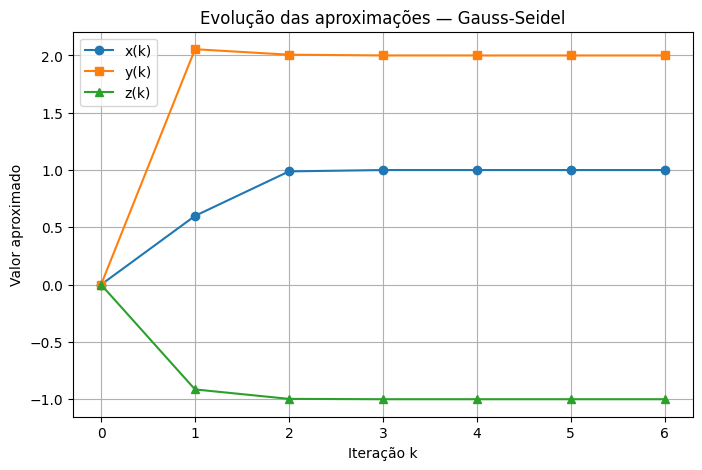

In [ ]:
import matplotlib.pyplot as plt

ks = np.arange(len(historico))
plt.figure(figsize=(8, 5))
plt.plot(ks, historico[:, 0], 'o-', label='x(k)')
plt.plot(ks, historico[:, 1], 's-', label='y(k)')
plt.plot(ks, historico[:, 2], '^-', label='z(k)')
plt.xlabel('Iteração k')
plt.ylabel('Valor aproximado')
plt.title('Evolução das aproximações — Gauss-Seidel')
plt.legend()
plt.grid(True)
plt.show()

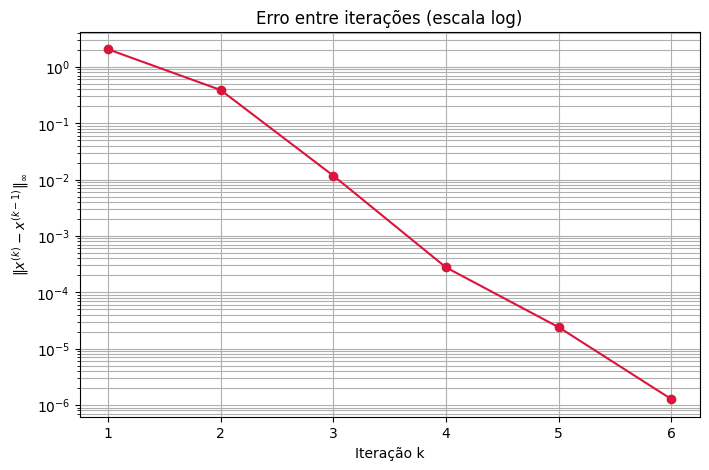

In [ ]:
plt.figure(figsize=(8, 5))
plt.semilogy(np.arange(1, len(erros) + 1), erros, 'o-', color='crimson')
plt.xlabel('Iteração k')
plt.ylabel(r'$\|x^{(k)} - x^{(k-1)}\|_\infty$')
plt.title('Erro entre iterações (escala log)')
plt.grid(True, which='both')
plt.show()